# IPL exploration: seasons, the toss, venues and home advantage

**Purpose:** a first look at the IPL match data before any modelling. It asks four questions:
1. How much data is there per season?
2. Does winning the toss help?
3. Do grounds differ?
4. Is there a home advantage?

**Rules for this notebook:**
- **No logic lives here.** Every number comes from tested functions in `cricket_value/analysis/explore.py`. The notebook only calls them and draws charts.
- **Every rate has a Wilson 95% interval.** One season is only about 60–74 matches, so a single season's rate is noisy.
- **Decided matches only.** No-results are left out, and a tie settled by a super over counts for the super-over winner.
- **Home status comes from the sourced reference data** (`config/reference/`). Neutral seasons (2009, the 2014 UAE leg, 2020–2022) never count as home or away.

Charts are also saved to `reports/figures/`. Re-run with `make notebook`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cricket_value.analysis import charts
from cricket_value.analysis.explore import (
    chases,
    chasing_effect,
    decided,
    first_innings_by_season,
    home_advantage,
    load_ipl,
    matches_per_season,
    pooled,
    rate_by,
    toss_decisions,
    toss_effect,
    venue_effects,
)
from cricket_value.ingest.manifest import Manifest
from cricket_value.reference.reference import load_reference

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = REPO / "reports" / "figures"
charts.apply_style()
pd.set_option("display.precision", 3)

matches, innings = load_ipl(REPO / "data" / "silver")
ref = load_reference(REPO / "config" / "reference")
print(f"raw snapshot: {Manifest(REPO / 'data' / 'raw' / 'manifest').snapshot_id()[:12]}")
seasons = f"{matches.season.min()}-{matches.season.max()}"
print(f"IPL matches: {len(matches):,}, decided: {len(decided(matches)):,}, {seasons}")

raw snapshot: 689eccf5c2f6
IPL matches: 1,243, decided: 1,234, 2008-2026


## 1. Matches per season

The league grew from 8 to 9 teams in 2011–2013, and to 10 teams from 2022. That changes how many matches each season contributes, and so how noisy each season's rates are.

,season,matches,no_result,super_over,dls
0,2008,58,0,0,2
1,2009,57,0,1,3
2,2010,60,0,1,0
3,2011,73,1,0,3
4,2012,74,0,0,0
5,2013,76,0,2,0
6,2014,60,0,1,1
7,2015,59,2,1,2
8,2016,60,0,0,4
9,2017,59,0,1,1


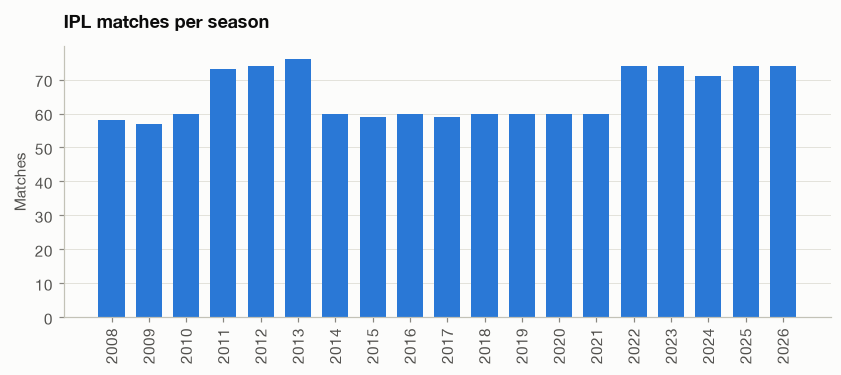

In [2]:
per_season = matches_per_season(matches)
fig, ax = plt.subplots(figsize=(9, 3.2))
charts.bars_over_seasons(
    ax,
    per_season["season"],
    per_season["matches"],
    title="IPL matches per season",
    ylabel="Matches",
)
charts.save(fig, "matches_per_season", FIGURES)
per_season

## 2. Scoring over time

The average first-innings total, using only full 20-over matches with no rain rule. This matters for everything that follows: a ground used mostly in high-scoring seasons will look high-scoring even if the ground itself isn't. The Impact Player rule arrived in 2023.

,season,avg_first_innings,n
0,2008,163.296,54
1,2009,150.333,54
2,2010,164.783,60
3,2011,155.551,69
4,2012,158.370,73
5,2013,156.560,75
6,2014,163.672,58
7,2015,168.167,54
8,2016,164.339,56
9,2017,166.431,58


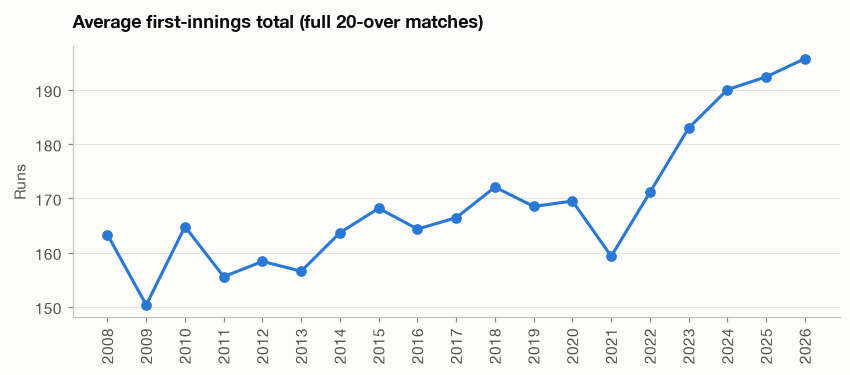

In [3]:
scoring = first_innings_by_season(matches, innings)
fig, ax = plt.subplots(figsize=(9, 3.2))
charts.line_over_seasons(
    ax,
    scoring["season"],
    scoring["avg_first_innings"],
    title="Average first-innings total (full 20-over matches)",
    ylabel="Runs",
)
charts.save(fig, "first_innings_by_season", FIGURES)
scoring

## 3. The toss

Two separate questions:
- **What do captains choose?** The share of toss winners who bowl first.
- **Does the choice pay off?** How often the toss winner goes on to win, and how often the side batting second wins.

A strong preference for fielding first only makes sense if chasing really is an advantage.

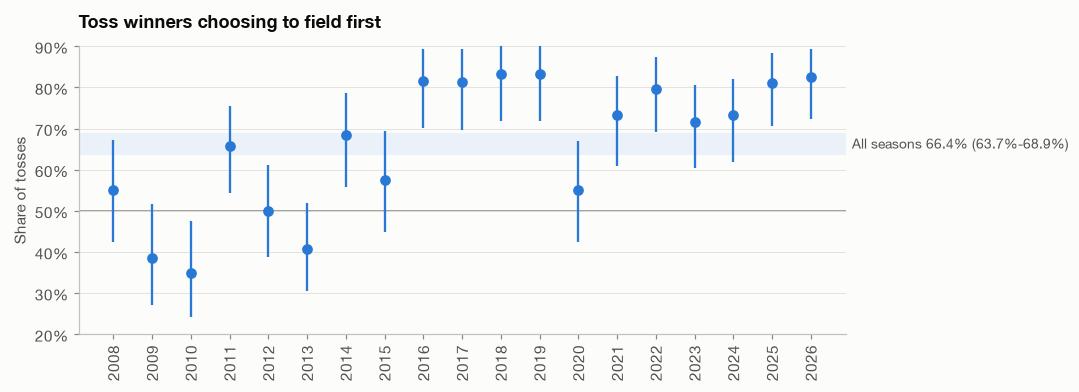

In [4]:
decisions = toss_decisions(matches)
fig, ax = plt.subplots(figsize=(9, 3.4))
charts.rate_over_seasons(
    ax,
    decisions,
    title="Toss winners choosing to field first",
    ylabel="Share of tosses",
    overall=pooled(matches.assign(f=matches.toss_decision == "field"), "f"),
)
charts.save(fig, "toss_choose_field", FIGURES)

,season,n,k,rate,low,high
0,2008,58,28,0.483,0.359,0.608
1,2009,57,33,0.579,0.450,0.698
2,2010,60,31,0.517,0.393,0.638
3,2011,72,38,0.528,0.414,0.639
4,2012,74,33,0.446,0.338,0.559
5,2013,76,36,0.474,0.365,0.584
6,2014,60,30,0.500,0.377,0.623
7,2015,57,28,0.491,0.366,0.617
8,2016,60,34,0.567,0.441,0.684
9,2017,59,34,0.576,0.449,0.694


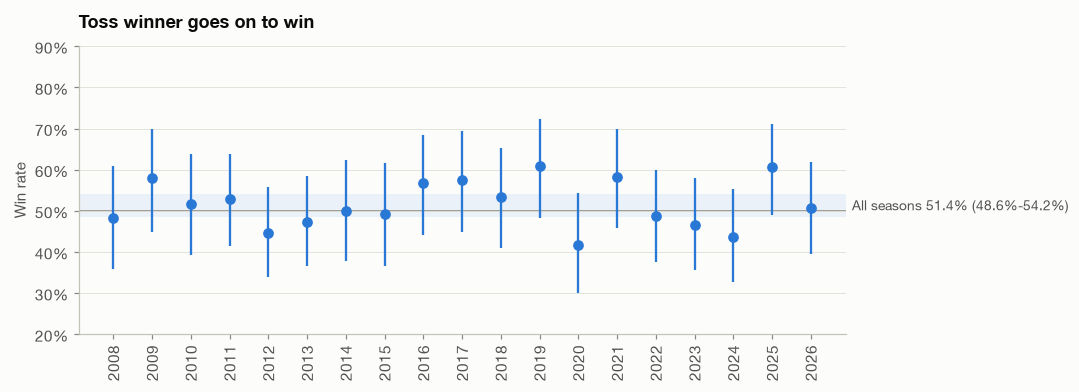

In [5]:
toss = toss_effect(matches)
toss_all = pooled(decided(matches).assign(won=lambda d: d.toss_winner == d.winner), "won")
fig, ax = plt.subplots(figsize=(9, 3.4))
charts.rate_over_seasons(
    ax, toss, title="Toss winner goes on to win", ylabel="Win rate", overall=toss_all
)
charts.save(fig, "toss_winner_wins", FIGURES)
toss

,season,n,k,rate,low,high
0,2008,58,36,0.621,0.492,0.734
1,2009,57,30,0.526,0.399,0.650
2,2010,60,28,0.467,0.346,0.591
3,2011,72,40,0.556,0.441,0.665
4,2012,74,40,0.541,0.428,0.649
5,2013,76,39,0.513,0.403,0.622
6,2014,60,37,0.617,0.490,0.729
7,2015,57,25,0.439,0.318,0.567
8,2016,60,41,0.683,0.558,0.787
9,2017,59,33,0.559,0.433,0.678


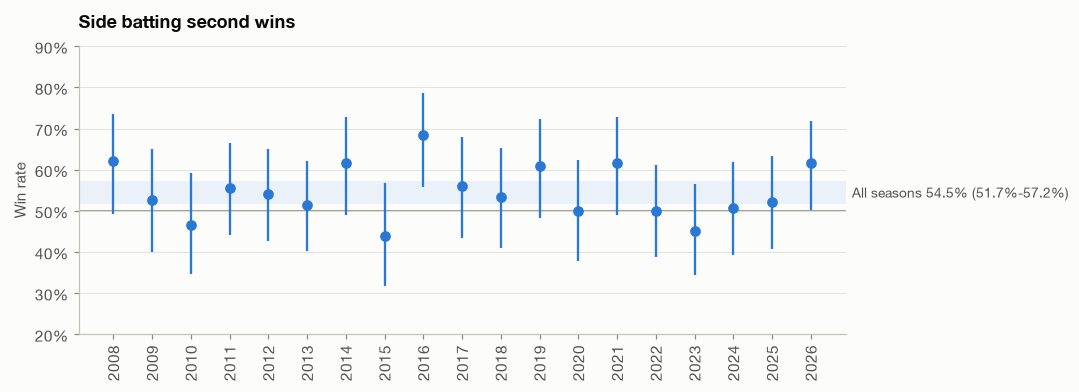

In [6]:
chase = chasing_effect(matches, innings)
chase_all = pooled(chases(matches, innings), "chase_won")
fig, ax = plt.subplots(figsize=(9, 3.4))
charts.rate_over_seasons(
    ax, chase, title="Side batting second wins", ylabel="Win rate", overall=chase_all
)
charts.save(fig, "chasing_side_wins", FIGURES)
chase

## 4. Venues

Grounds with at least 20 decided matches, after merging name variants (for example Feroz Shah Kotla is now Arun Jaitley Stadium).

**Caveat:** a ground's average total mixes the eras it was used in. A ground used mostly since 2023 will look high-scoring because of the era (see section 2), not only because of the ground. Venue effects should therefore be modelled together with season, not read off this table.

,canonical_name,city,matches,chase_win_rate,chase_low,chase_high,avg_first_innings,first_innings_n
0,Wankhede Stadium,Mumbai,132,0.545,0.460,0.628,173.267,131
1,Eden Gardens,Kolkata,105,0.571,0.476,0.662,172.515,99
2,Arun Jaitley Stadium,Delhi,103,0.534,0.438,0.627,173.500,100
3,M Chinnaswamy Stadium,Bengaluru,101,0.564,0.467,0.657,178.716,95
4,MA Chidambaram Stadium,Chennai,98,0.459,0.364,0.558,165.561,98
5,Rajiv Gandhi International Stadium,Hyderabad,89,0.551,0.447,0.650,169.713,87
6,Sawai Mansingh Stadium,Jaipur,68,0.647,0.528,0.750,169.299,67
7,Punjab Cricket Association IS Bindra Stadium,Mohali,61,0.557,0.433,0.675,168.949,59
8,Maharashtra Cricket Association Stadium,Pune,51,0.451,0.323,0.586,162.373,51
9,Dubai International Cricket Stadium,Dubai,46,0.500,0.361,0.639,163.761,46


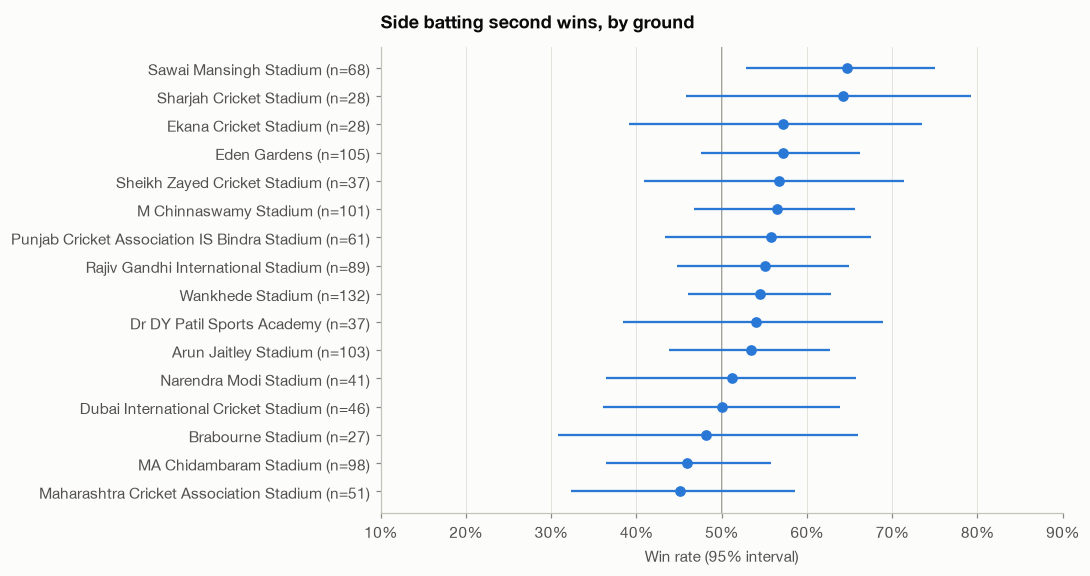

In [7]:
venues = venue_effects(matches, innings, ref, min_matches=20)
fig, ax = plt.subplots(figsize=(8, 5.5))
charts.rate_by_group(
    ax,
    venues.rename(
        columns={"chase_win_rate": "rate", "chase_low": "low", "chase_high": "high", "matches": "n"}
    ),
    "canonical_name",
    title="Side batting second wins, by ground",
    xlabel="Win rate (95% interval)",
)
charts.save(fig, "chasing_by_venue", FIGURES)
venues[
    [
        "canonical_name",
        "city",
        "matches",
        "chase_win_rate",
        "chase_low",
        "chase_high",
        "avg_first_innings",
        "first_innings_n",
    ]
]

## 5. Home advantage

Only matches where exactly one side was at home count, so neutral seasons and neutral grounds are excluded. For comparison, the Elo baseline (`reports/elo_baseline.md`) tuned a home bonus of 30–45 rating points, which is about 54–56% for the home side.

**Caveat for the franchise chart:** a franchise's home win rate mixes home advantage with team strength. A strong team wins often at home *and* away. To isolate the home effect, compare each team's home and away results, or let a model with team strength estimate it, as the Elo home bonus does.

home side won 53.1% of 915 matches (49.9%-56.3%)


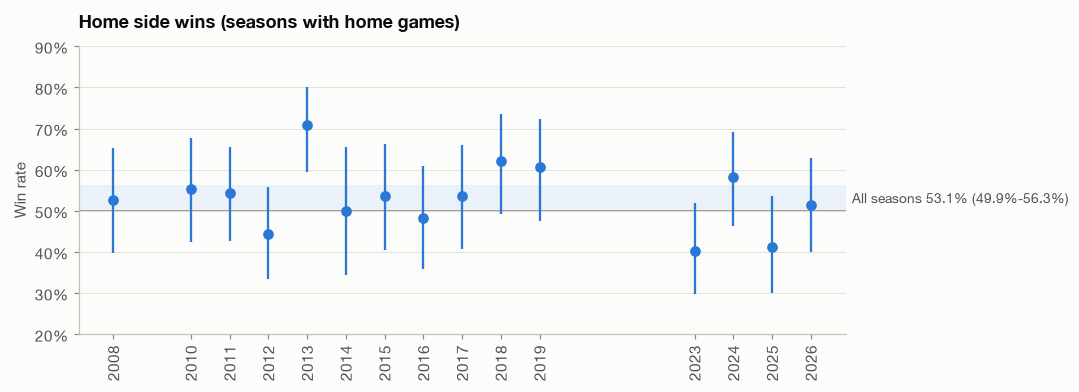

In [8]:
home = home_advantage(matches, ref)
home_all = pooled(home, "home_won")
fig, ax = plt.subplots(figsize=(9, 3.4))
charts.rate_over_seasons(
    ax,
    rate_by(home, "season", "home_won"),
    title="Home side wins (seasons with home games)",
    ylabel="Win rate",
    overall=home_all,
)
charts.save(fig, "home_win_rate_by_season", FIGURES)
interval = f"{home_all['low']:.1%}-{home_all['high']:.1%}"
print(f"home side won {home_all['rate']:.1%} of {home_all['n']} matches ({interval})")

,franchise,n,rate,low,high
0,Chennai Super Kings,94,0.660,0.559,0.747
8,Mumbai Indians,108,0.611,0.517,0.698
14,Sunrisers Hyderabad,72,0.611,0.496,0.715
13,Rajasthan Royals,89,0.596,0.492,0.691
5,Kolkata Knight Riders,102,0.569,0.472,0.661
4,Gujarat Titans,30,0.567,0.392,0.726
11,Royal Challengers Bengaluru,99,0.525,0.428,0.621
12,Rising Pune Supergiant,14,0.500,0.268,0.732
1,Delhi Capitals,103,0.456,0.363,0.552
9,Punjab Kings,104,0.452,0.360,0.548


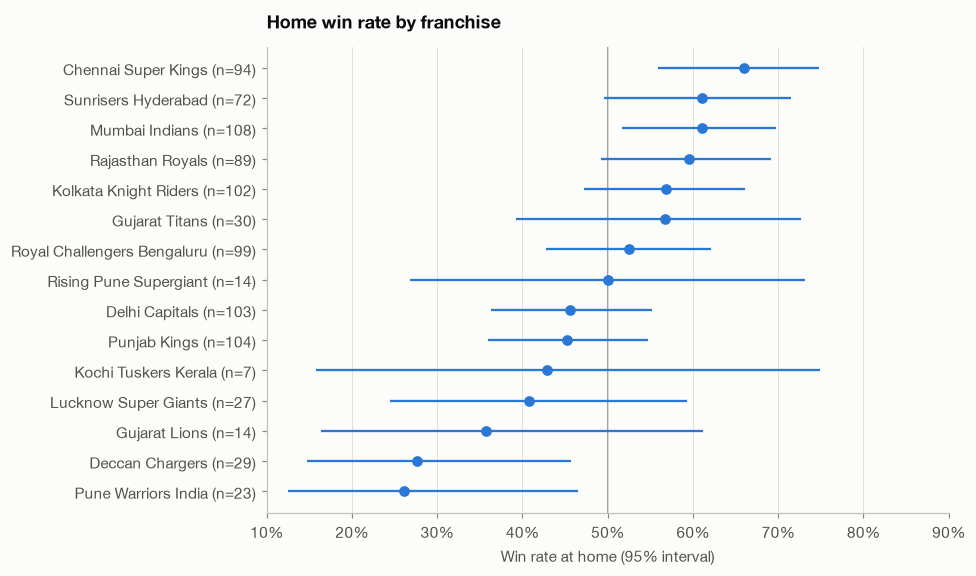

In [9]:
names = ref.franchises.set_index("franchise_id")["franchise_name"]
by_team = rate_by(home, "home_franchise", "home_won")
by_team["franchise"] = by_team["home_franchise"].map(names)
fig, ax = plt.subplots(figsize=(8, 5.5))
charts.rate_by_group(
    ax,
    by_team,
    "franchise",
    title="Home win rate by franchise",
    xlabel="Win rate at home (95% interval)",
)
charts.save(fig, "home_win_rate_by_franchise", FIGURES)
by_team.sort_values("rate", ascending=False)[["franchise", "n", "rate", "low", "high"]]

## 6. Summary

The table below is computed from the data above, so it stays correct when the data is rebuilt. A result counts as an effect only if its 95% interval excludes 50%.

In [10]:
def verdict(r):
    return (
        "above 50%" if r["low"] > 0.5 else ("below 50%" if r["high"] < 0.5 else "no clear effect")
    )


summary = pd.DataFrame(
    [
        {
            "question": "Toss winner chooses to field",
            **pooled(matches.assign(f=matches.toss_decision == "field"), "f"),
        },
        {"question": "Toss winner wins", **toss_all},
        {"question": "Side batting second wins", **chase_all},
        {"question": "Home side wins", **home_all},
    ]
)
summary["verdict"] = summary.apply(verdict, axis=1)
summary

,question,n,rate,low,high,verdict
0,Toss winner chooses to field,1243,0.664,0.637,0.689,above 50%
1,Toss winner wins,1234,0.514,0.486,0.542,no clear effect
2,Side batting second wins,1234,0.545,0.517,0.572,above 50%
3,Home side wins,915,0.531,0.499,0.563,no clear effect


### What this means for the models

- **The toss itself barely matters, but the choice it allows might.** Most toss winners now field first, and chasing wins slightly more often than not. So the win model should use *who bats second*, which is known at the toss, rather than *who won the toss*.
- **Home advantage is small,** and on its own may not be distinguishable from 50%. This agrees with the Elo baseline: team-level signals are weak, which is why the project's edge has to come from player ratings.
- **Season and venue are confounded through scoring inflation.** Venue effects need to be estimated within an era, not from raw averages.
- **Per-season and per-team rates are noisy.** Most single-season intervals span about 25 percentage points, so they shouldn't be read individually.